# 🚗 Road accidents: exploratory data analysis
**SolveX 3.0, Problématique 1: Accidents de la route**

Before training a risk model, we look at the data to understand **when, where and in which conditions** accidents happen, and which of them are the most serious.

**Data:** French national road accident database (BAAC, ONISR, data.gouv.fr), 2016–2024, merged into one row per accident by `merge_baac.py`.

**Plan**
1. Overview & data quality
2. When do accidents happen?
3. How serious are they?
4. Conditions: light & weather
5. The road: type, shape, intersections, speed
6. Where: map & black spots
7. How accidents happen (collision types)
8. The exposure lesson: counts vs real risk
9. Key findings

In [4]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["axes.titleweight"] = "bold"
RED, BLUE, GREY = "#c0392b", "#2c6fbb", "#95a5a6"

def find(name):
    """Finds a file in Kaggle inputs (/kaggle/input/...) or in the current folder."""
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(name)
    return hits[0] if hits else None

ACC_PATH = find("/kaggle/input/datasets/moussaballou/accidents-2016-2024-csv/accidents_2016_2024.csv")
TRAIN_PATH = find("/kaggle/input/datasets/moussaballou/training-table-csv/training_table.csv")   # optional, used in part 8
print("Accidents file:", ACC_PATH)
print("Training table:", TRAIN_PATH or "not found (part 8 will be skipped)")

Accidents file: /kaggle/input/datasets/moussaballou/accidents-2016-2024-csv/accidents_2016_2024.csv
Training table: /kaggle/input/datasets/moussaballou/training-table-csv/training_table.csv


In [5]:
df = pd.read_csv(ACC_PATH, low_memory=False)
df = df[df["is_metro"]].copy()                       # mainland France only
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["fatal"] = df["post_fatal"]
print(f"{len(df):,} accidents in mainland France, {df.shape[1]} columns")

# Readable labels for the BAAC codes
LABELS = {
    "lum":  {1: "Daylight", 2: "Dusk / dawn", 3: "Night, no street light",
             4: "Night, lights off", 5: "Night, lights on"},
    "atm":  {1: "Normal", 2: "Light rain", 3: "Heavy rain", 4: "Snow / hail",
             5: "Fog / smoke", 6: "Strong wind", 7: "Dazzling", 8: "Overcast", 9: "Other"},
    "catr": {1: "Motorway", 2: "National road", 3: "Departmental road", 4: "Municipal road",
             5: "Off public network", 6: "Parking lot", 7: "Urban metropole road", 9: "Other"},
    "plan": {1: "Straight", 2: "Left curve", 3: "Right curve", 4: "S-bend"},
    "int":  {1: "No intersection", 2: "X junction", 3: "T junction", 4: "Y junction",
             5: "5+ branches", 6: "Roundabout", 7: "Square", 8: "Railway crossing", 9: "Other"},
    "agg":  {1: "Outside town", 2: "In town"},
    "col":  {1: "Head-on (2 veh.)", 2: "Rear-end (2 veh.)", 3: "Side (2 veh.)",
             4: "Chain (3+ veh.)", 5: "Multiple (3+ veh.)", 6: "Other collision", 7: "No collision"},
    "surf": {1: "Normal", 2: "Wet", 3: "Puddles", 4: "Flooded", 5: "Snow",
             6: "Mud", 7: "Icy", 8: "Oil / grease", 9: "Other"},
}
for col, m in LABELS.items():
    if col in df.columns:
        df[col + "_lbl"] = df[col].map(m)

DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

481,657 accidents in mainland France, 49 columns


## 1. Overview & data quality
Which columns are often empty? This tells us which features we can rely on.

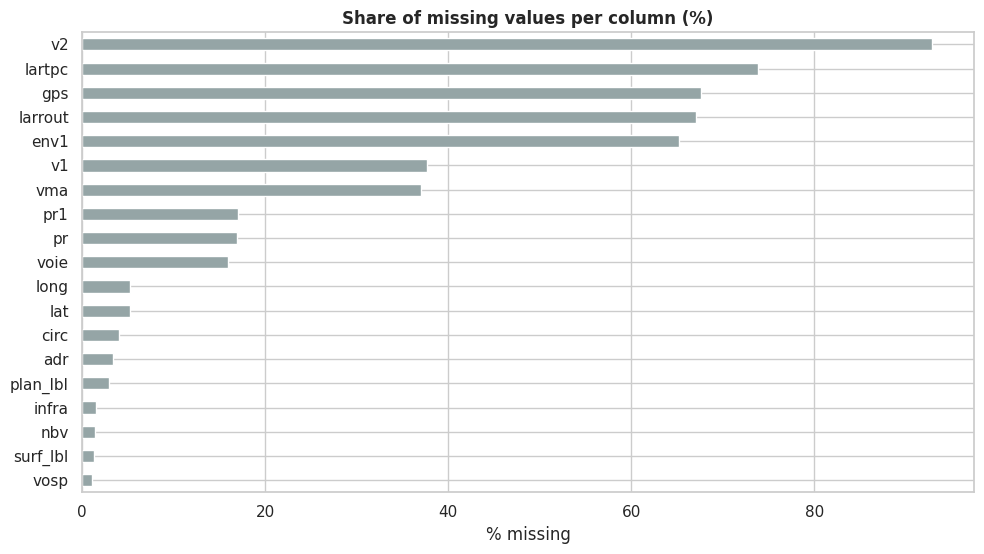

Note: 'vma' (speed limit) only exists from 2019, so ~1/3 missing is expected.


In [6]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0.01]
ax = (miss * 100).plot.barh(color=GREY, figsize=(10, max(3, len(miss) * 0.3)))
ax.set_title("Share of missing values per column (%)")
ax.set_xlabel("% missing"); ax.invert_yaxis()
plt.tight_layout(); plt.show()
print("Note: 'vma' (speed limit) only exists from 2019, so ~1/3 missing is expected.")

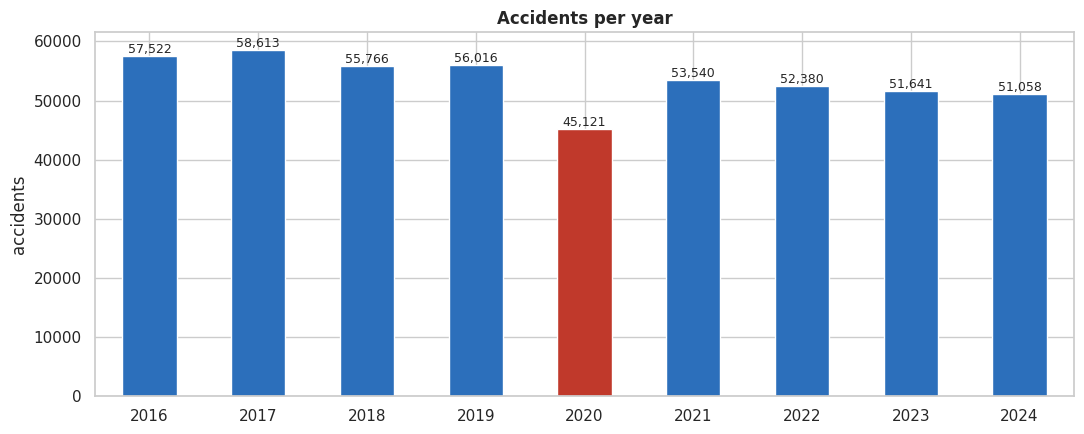

2020 (red) is low because of the COVID lockdowns: less traffic, fewer accidents.


In [7]:
per_year = df.groupby("year").size()
ax = per_year.plot.bar(color=[RED if y == 2020 else BLUE for y in per_year.index], rot=0)
ax.set_title("Accidents per year"); ax.set_ylabel("accidents"); ax.set_xlabel("")
for i, v in enumerate(per_year):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()
print("2020 (red) is low because of the COVID lockdowns: less traffic, fewer accidents.")

## 2. When do accidents happen?
⚠️ These are **raw counts**. More accidents at a given hour can simply mean **more cars on the road**. Part 8 corrects for that.

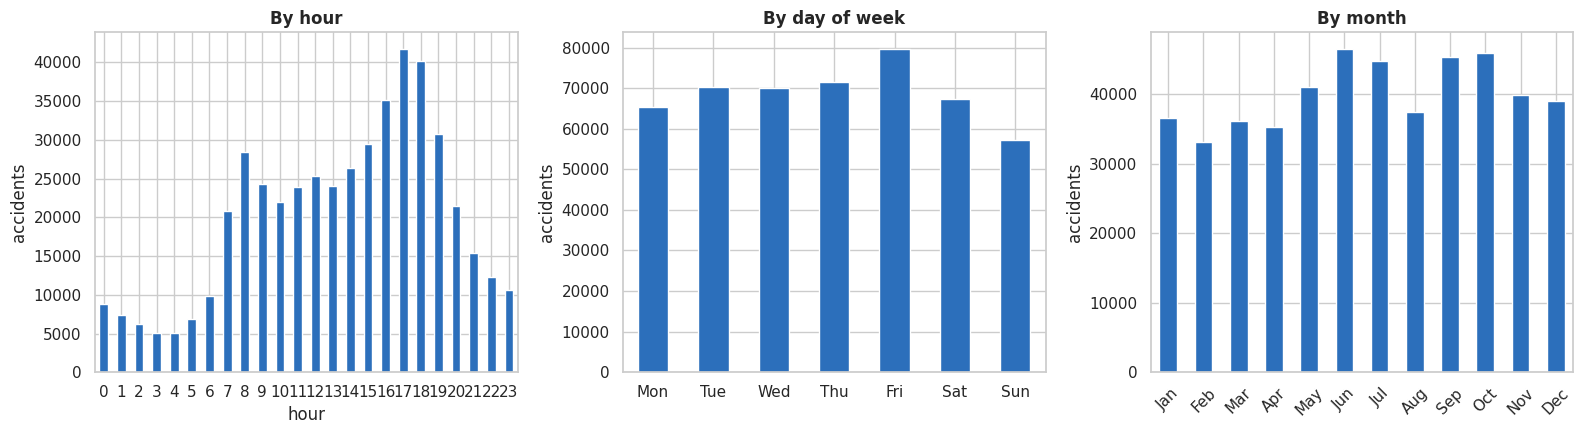

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
df.groupby("hour").size().plot.bar(ax=axes[0], color=BLUE, rot=0)
axes[0].set_title("By hour"); axes[0].set_xlabel("hour")
wd = df.groupby(df["date"].dt.day_of_week).size(); wd.index = DAYS
wd.plot.bar(ax=axes[1], color=BLUE, rot=0); axes[1].set_title("By day of week")
mo = df.groupby(df["date"].dt.month).size(); mo.index = MONTHS
mo.plot.bar(ax=axes[2], color=BLUE, rot=45); axes[2].set_title("By month")
for a in axes: a.set_ylabel("accidents")
plt.tight_layout(); plt.show()

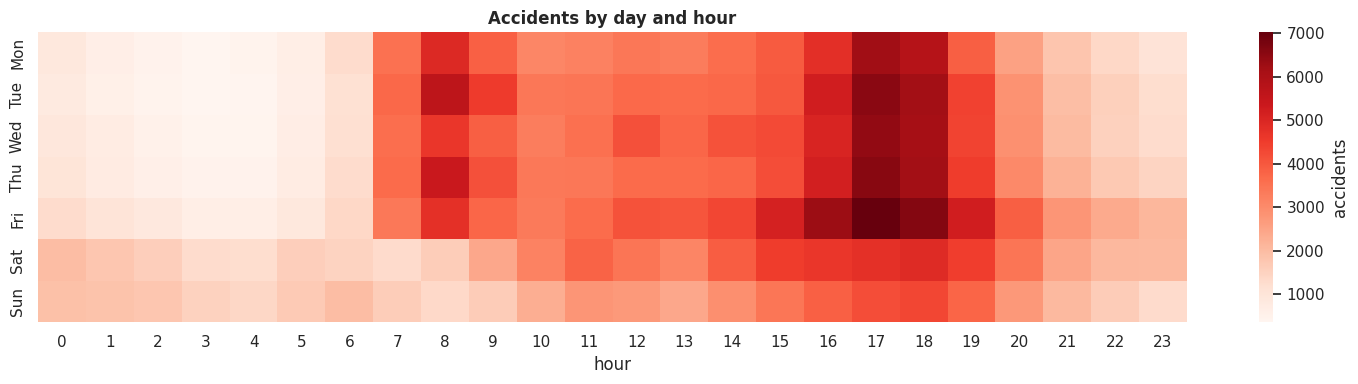

Look for: weekday rush hours (8h, 17-18h) and weekend nights (Fri/Sat/Sun 0-5h).


In [9]:
heat = df.pivot_table(index=df["date"].dt.day_of_week, columns="hour",
                      values="Num_Acc", aggfunc="count")
heat.index = DAYS
plt.figure(figsize=(15, 4))
sns.heatmap(heat, cmap="Reds", cbar_kws={"label": "accidents"})
plt.title("Accidents by day and hour"); plt.ylabel(""); plt.xlabel("hour")
plt.tight_layout(); plt.show()
print("Look for: weekday rush hours (8h, 17-18h) and weekend nights (Fri/Sat/Sun 0-5h).")

## 3. How serious are accidents?
`fatal` = at least one person killed. Fewer accidents happen at night, but are they **deadlier**?

Fatal accidents: 5.6% of all accidents


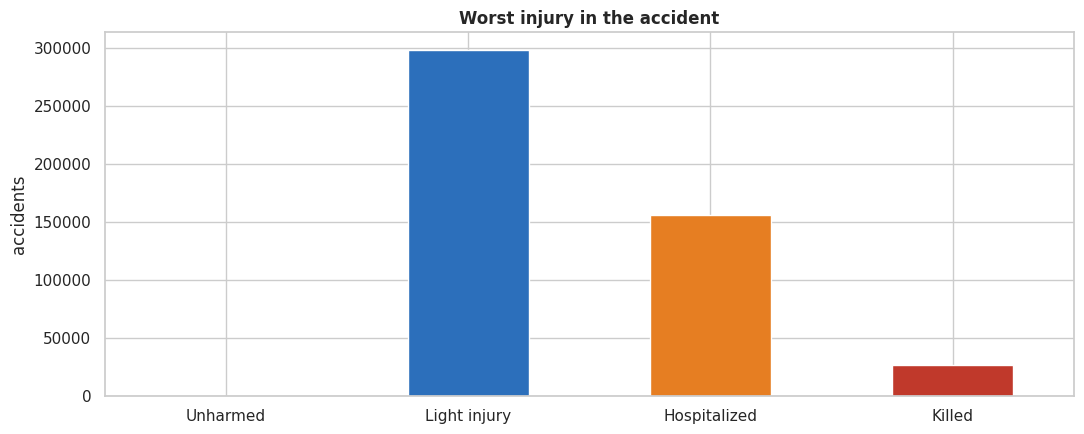

In [10]:
print(f"Fatal accidents: {df['fatal'].mean():.1%} of all accidents")
sev = df["post_max_severity"].map({0: "Unharmed", 1: "Light injury",
                                   2: "Hospitalized", 3: "Killed"}).value_counts()
sev = sev.reindex(["Unharmed", "Light injury", "Hospitalized", "Killed"])
ax = sev.plot.bar(color=[GREY, BLUE, "#e67e22", RED], rot=0)
ax.set_title("Worst injury in the accident"); ax.set_ylabel("accidents"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

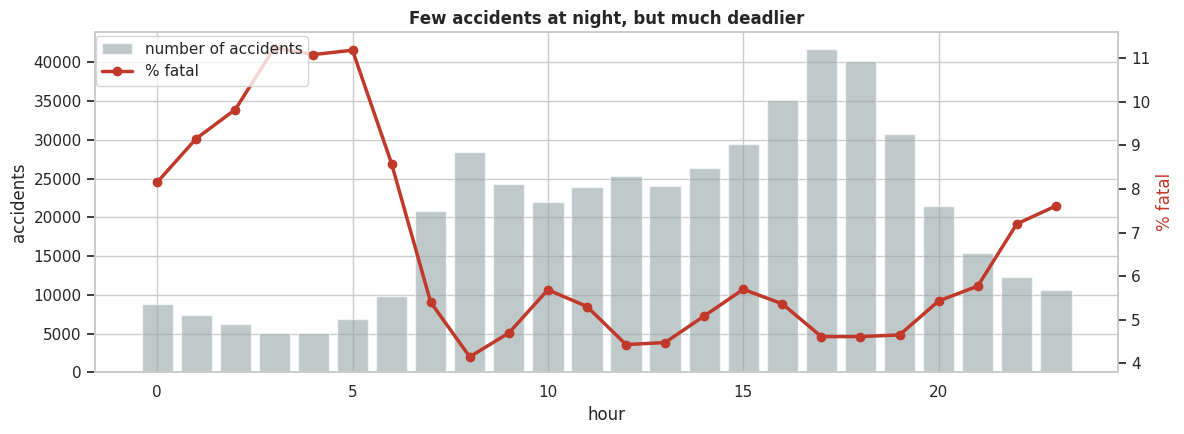

In [11]:
fig, ax1 = plt.subplots(figsize=(12, 4.5))
by_h = df.groupby("hour").agg(n=("fatal", "size"), fatal=("fatal", "mean"))
ax1.bar(by_h.index, by_h["n"], color=GREY, alpha=0.6, label="number of accidents")
ax1.set_ylabel("accidents"); ax1.set_xlabel("hour")
ax2 = ax1.twinx()
ax2.plot(by_h.index, by_h["fatal"] * 100, color=RED, marker="o", lw=2.5, label="% fatal")
ax2.set_ylabel("% fatal", color=RED); ax2.grid(False)
plt.title("Few accidents at night, but much deadlier")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92)); plt.tight_layout(); plt.show()

## 4. Conditions: light & weather
Left: how many accidents. Right: how deadly they are. The **right** chart is the interesting one.

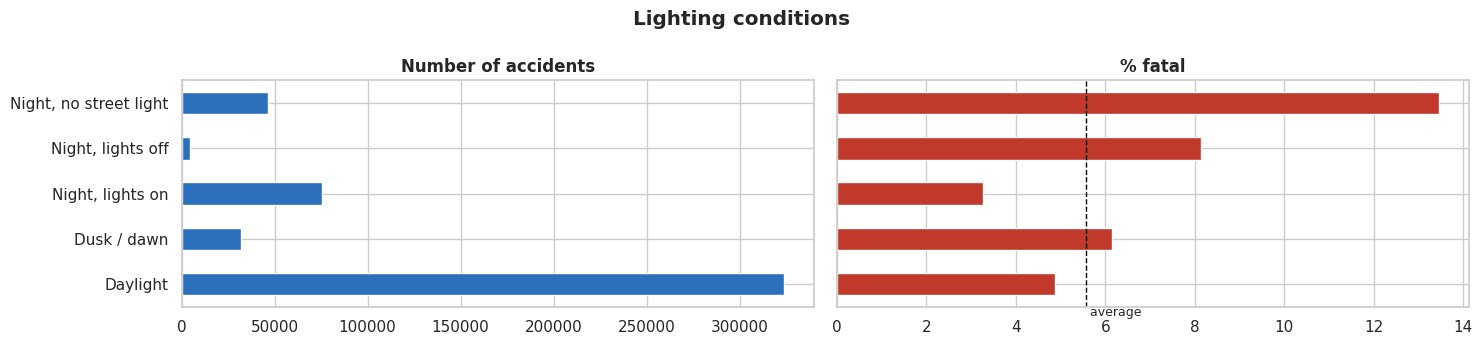

In [12]:
g = df.groupby("lum_lbl").agg(accidents=("fatal", "size"), fatal_pct=("fatal", "mean"))
g = g[g["accidents"] >= 500]
g = g.reindex([x for x in ['Daylight', 'Dusk / dawn', 'Night, lights on', 'Night, lights off', 'Night, no street light'] if x in g.index])
fig, axes = plt.subplots(1, 2, figsize=(15, max(3.5, len(g) * 0.42)))
g["accidents"].plot.barh(ax=axes[0], color=BLUE); axes[0].set_title("Number of accidents")
(g["fatal_pct"] * 100).plot.barh(ax=axes[1], color=RED); axes[1].set_title("% fatal")
avg = df["fatal"].mean() * 100
axes[1].axvline(avg, color="black", ls="--", lw=1); axes[1].text(avg, -0.7, " average", fontsize=9)
axes[1].set_yticklabels([])
for a in axes: a.set_ylabel("")
fig.suptitle("Lighting conditions", fontweight="bold"); plt.tight_layout(); plt.show()

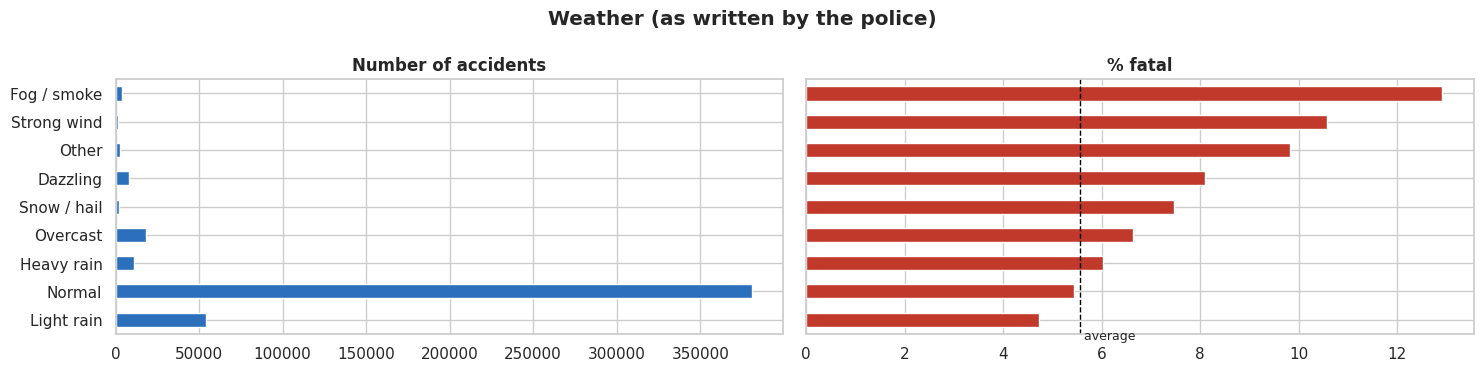

In [13]:
g = df.groupby("atm_lbl").agg(accidents=("fatal", "size"), fatal_pct=("fatal", "mean"))
g = g[g["accidents"] >= 500]
g = g.sort_values('fatal_pct')
fig, axes = plt.subplots(1, 2, figsize=(15, max(3.5, len(g) * 0.42)))
g["accidents"].plot.barh(ax=axes[0], color=BLUE); axes[0].set_title("Number of accidents")
(g["fatal_pct"] * 100).plot.barh(ax=axes[1], color=RED); axes[1].set_title("% fatal")
avg = df["fatal"].mean() * 100
axes[1].axvline(avg, color="black", ls="--", lw=1); axes[1].text(avg, -0.7, " average", fontsize=9)
axes[1].set_yticklabels([])
for a in axes: a.set_ylabel("")
fig.suptitle("Weather (as written by the police)", fontweight="bold"); plt.tight_layout(); plt.show()

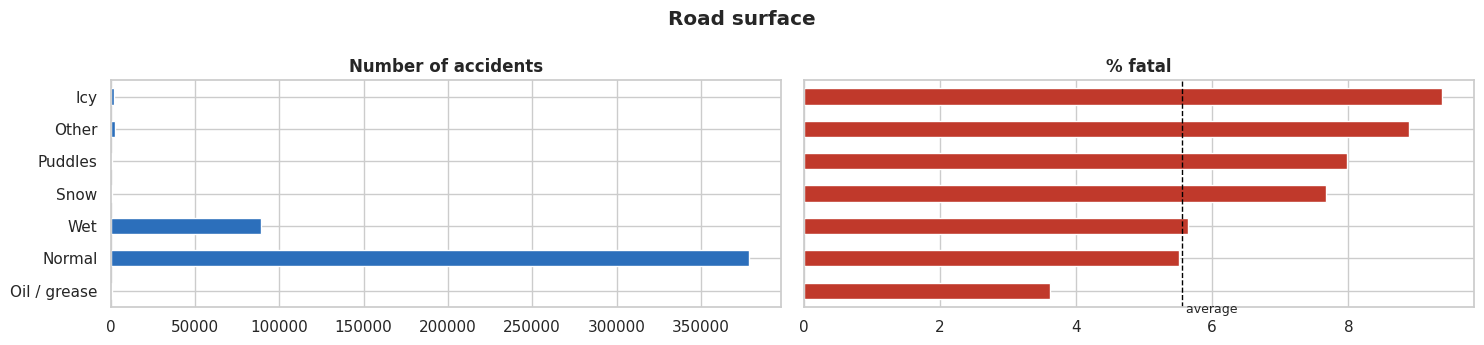

In [14]:
g = df.groupby("surf_lbl").agg(accidents=("fatal", "size"), fatal_pct=("fatal", "mean"))
g = g[g["accidents"] >= 500]
g = g.sort_values('fatal_pct')
fig, axes = plt.subplots(1, 2, figsize=(15, max(3.5, len(g) * 0.42)))
g["accidents"].plot.barh(ax=axes[0], color=BLUE); axes[0].set_title("Number of accidents")
(g["fatal_pct"] * 100).plot.barh(ax=axes[1], color=RED); axes[1].set_title("% fatal")
avg = df["fatal"].mean() * 100
axes[1].axvline(avg, color="black", ls="--", lw=1); axes[1].text(avg, -0.7, " average", fontsize=9)
axes[1].set_yticklabels([])
for a in axes: a.set_ylabel("")
fig.suptitle("Road surface", fontweight="bold"); plt.tight_layout(); plt.show()

## 5. The road itself
These are the features we can also get for **Algerian roads** from OpenStreetMap.

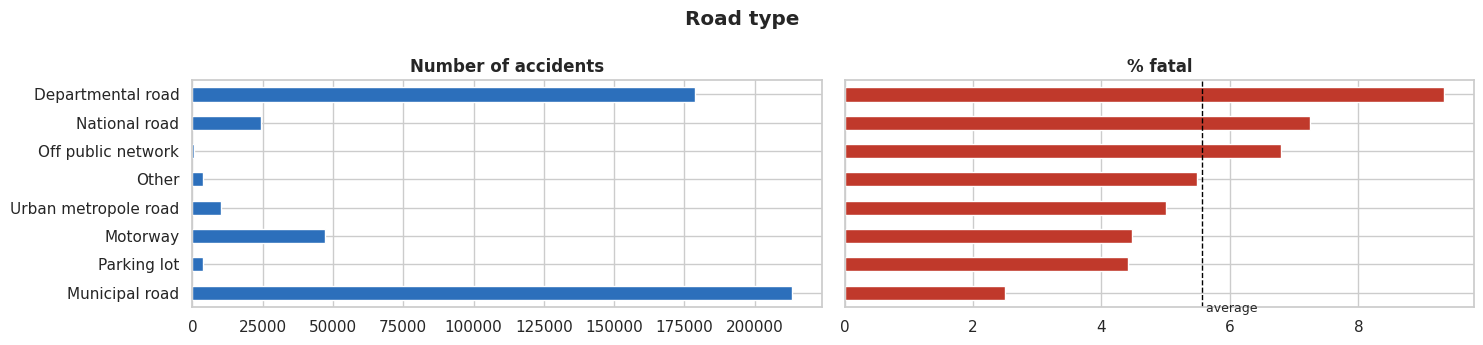

In [15]:
g = df.groupby("catr_lbl").agg(accidents=("fatal", "size"), fatal_pct=("fatal", "mean"))
g = g[g["accidents"] >= 500]
g = g.sort_values('fatal_pct')
fig, axes = plt.subplots(1, 2, figsize=(15, max(3.5, len(g) * 0.42)))
g["accidents"].plot.barh(ax=axes[0], color=BLUE); axes[0].set_title("Number of accidents")
(g["fatal_pct"] * 100).plot.barh(ax=axes[1], color=RED); axes[1].set_title("% fatal")
avg = df["fatal"].mean() * 100
axes[1].axvline(avg, color="black", ls="--", lw=1); axes[1].text(avg, -0.7, " average", fontsize=9)
axes[1].set_yticklabels([])
for a in axes: a.set_ylabel("")
fig.suptitle("Road type", fontweight="bold"); plt.tight_layout(); plt.show()

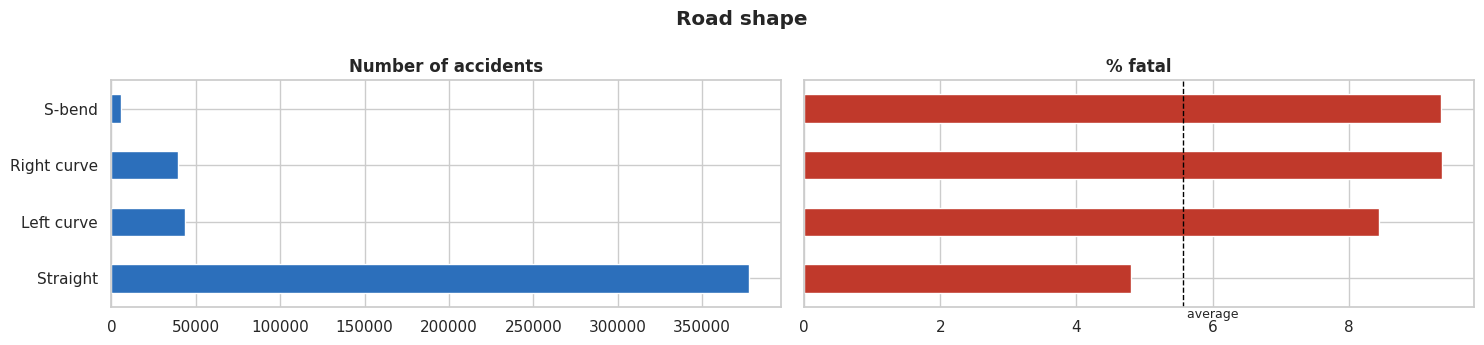

In [16]:
g = df.groupby("plan_lbl").agg(accidents=("fatal", "size"), fatal_pct=("fatal", "mean"))
g = g[g["accidents"] >= 500]
g = g.reindex([x for x in ['Straight', 'Left curve', 'Right curve', 'S-bend'] if x in g.index])
fig, axes = plt.subplots(1, 2, figsize=(15, max(3.5, len(g) * 0.42)))
g["accidents"].plot.barh(ax=axes[0], color=BLUE); axes[0].set_title("Number of accidents")
(g["fatal_pct"] * 100).plot.barh(ax=axes[1], color=RED); axes[1].set_title("% fatal")
avg = df["fatal"].mean() * 100
axes[1].axvline(avg, color="black", ls="--", lw=1); axes[1].text(avg, -0.7, " average", fontsize=9)
axes[1].set_yticklabels([])
for a in axes: a.set_ylabel("")
fig.suptitle("Road shape", fontweight="bold"); plt.tight_layout(); plt.show()

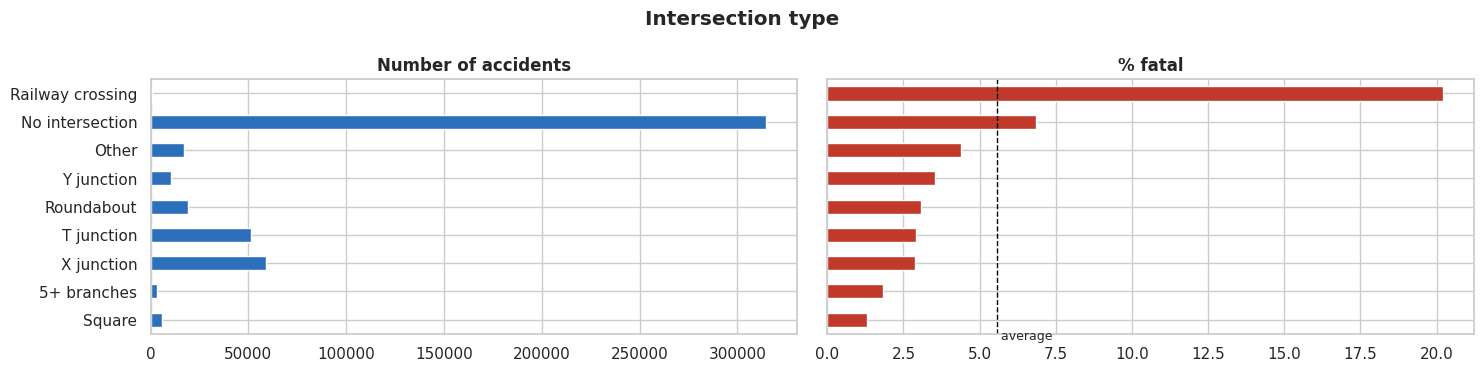

In [17]:
g = df.groupby("int_lbl").agg(accidents=("fatal", "size"), fatal_pct=("fatal", "mean"))
g = g[g["accidents"] >= 500]
g = g.sort_values('fatal_pct')
fig, axes = plt.subplots(1, 2, figsize=(15, max(3.5, len(g) * 0.42)))
g["accidents"].plot.barh(ax=axes[0], color=BLUE); axes[0].set_title("Number of accidents")
(g["fatal_pct"] * 100).plot.barh(ax=axes[1], color=RED); axes[1].set_title("% fatal")
avg = df["fatal"].mean() * 100
axes[1].axvline(avg, color="black", ls="--", lw=1); axes[1].text(avg, -0.7, " average", fontsize=9)
axes[1].set_yticklabels([])
for a in axes: a.set_ylabel("")
fig.suptitle("Intersection type", fontweight="bold"); plt.tight_layout(); plt.show()

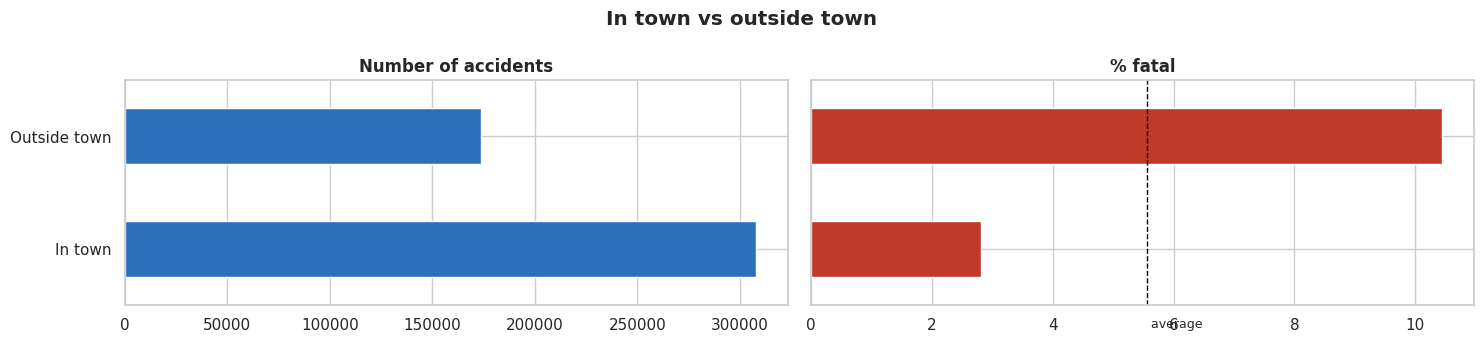

In [18]:
g = df.groupby("agg_lbl").agg(accidents=("fatal", "size"), fatal_pct=("fatal", "mean"))
g = g[g["accidents"] >= 500]
g = g.reindex([x for x in ['In town', 'Outside town'] if x in g.index])
fig, axes = plt.subplots(1, 2, figsize=(15, max(3.5, len(g) * 0.42)))
g["accidents"].plot.barh(ax=axes[0], color=BLUE); axes[0].set_title("Number of accidents")
(g["fatal_pct"] * 100).plot.barh(ax=axes[1], color=RED); axes[1].set_title("% fatal")
avg = df["fatal"].mean() * 100
axes[1].axvline(avg, color="black", ls="--", lw=1); axes[1].text(avg, -0.7, " average", fontsize=9)
axes[1].set_yticklabels([])
for a in axes: a.set_ylabel("")
fig.suptitle("In town vs outside town", fontweight="bold"); plt.tight_layout(); plt.show()

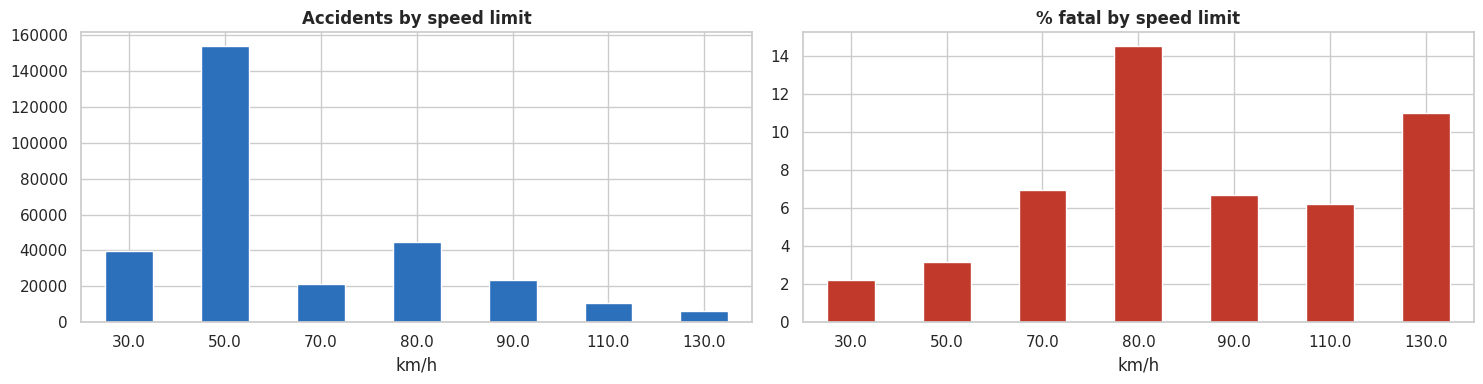

Expected: the faster the road, the deadlier the accident (physics: energy grows with speed²).


In [19]:
v = df.dropna(subset=["vma"])
v = v[v["vma"].isin([30, 50, 70, 80, 90, 110, 130])]
g = v.groupby("vma").agg(accidents=("fatal", "size"), fatal_pct=("fatal", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
g["accidents"].plot.bar(ax=axes[0], color=BLUE, rot=0); axes[0].set_title("Accidents by speed limit")
(g["fatal_pct"] * 100).plot.bar(ax=axes[1], color=RED, rot=0); axes[1].set_title("% fatal by speed limit")
for a in axes: a.set_xlabel("km/h")
plt.tight_layout(); plt.show()
print("Expected: the faster the road, the deadlier the accident (physics: energy grows with speed²).")

## 6. Where: map & black spots
Each dot-density cell shows where accidents concentrate. Cities stand out, but so do **specific roads**.

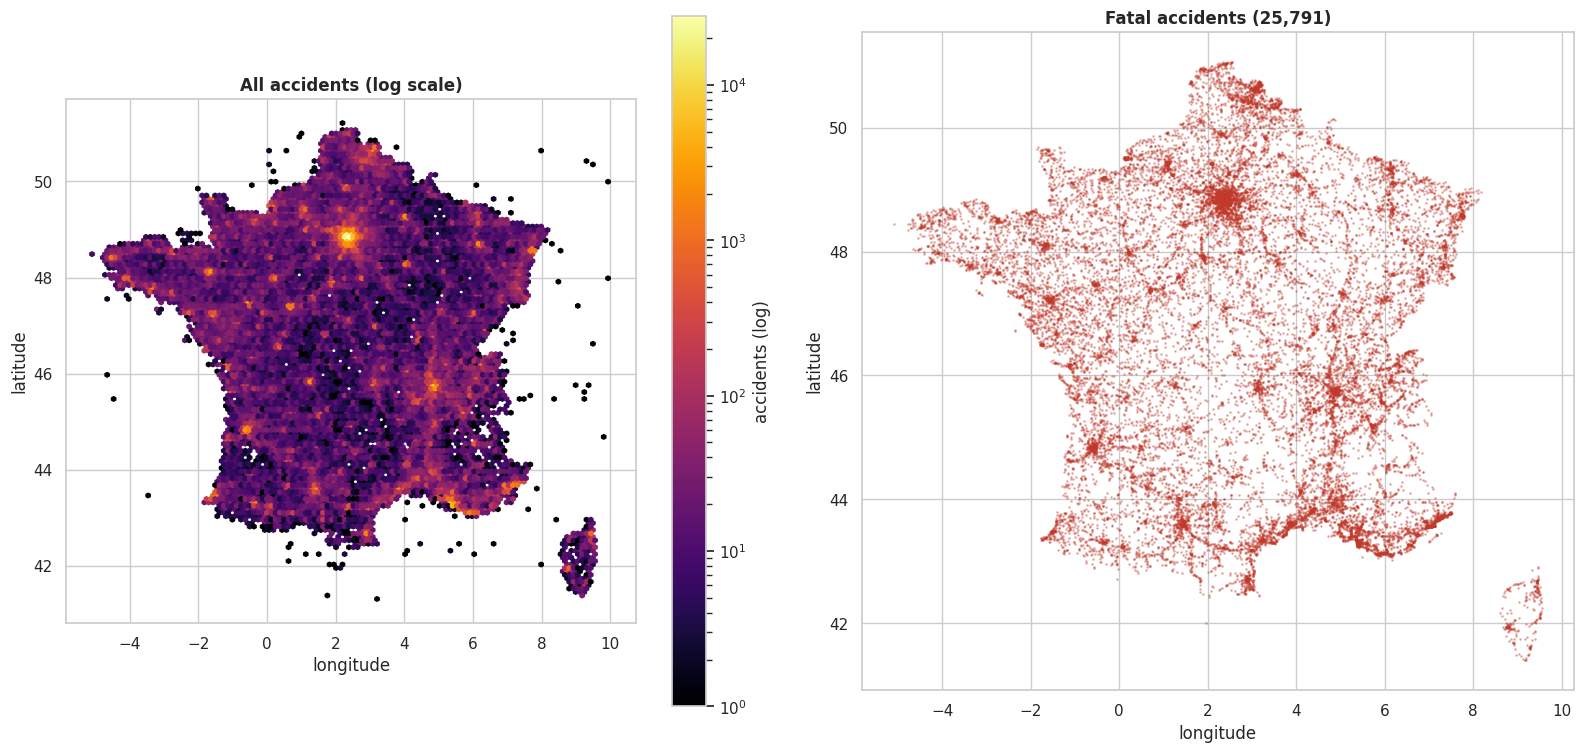

In [20]:
geo = df.dropna(subset=["lat", "long"])
geo = geo[geo["lat"].between(41, 51.5) & geo["long"].between(-5.5, 10)]
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
hb = axes[0].hexbin(geo["long"], geo["lat"], gridsize=120, bins="log", cmap="inferno", mincnt=1)
axes[0].set_title("All accidents (log scale)"); fig.colorbar(hb, ax=axes[0], label="accidents (log)")
f = geo[geo["fatal"] == 1]
axes[1].scatter(f["long"], f["lat"], s=1, alpha=0.3, color=RED)
axes[1].set_title(f"Fatal accidents ({len(f):,})")
for a in axes:
    a.set_xlabel("longitude"); a.set_ylabel("latitude"); a.set_aspect(1.4)
plt.tight_layout(); plt.show()

In [21]:
# Black spots: 500 m squares with the most accidents OUTSIDE towns (roads, not city centres)
rural = geo[geo["agg"] == 1].copy()
rural["cell"] = (np.floor(rural["lat"] / 0.0045).astype(int).astype(str) + "_"
                 + np.floor(rural["long"] / 0.0065).astype(int).astype(str))
spots = (rural.groupby("cell")
         .agg(accidents=("fatal", "size"), fatal=("fatal", "sum"),
              road=("adr", lambda s: s.mode().iloc[0] if s.notna().any() else ""),
              dep=("dep", "first"), lat=("lat", "mean"), lon=("long", "mean"))
         .sort_values("accidents", ascending=False))
print("Top 15 black spots outside towns (500 m squares):")
display(spots.head(15).round(4))

counts = spots["accidents"].value_counts().sort_index()
share_1 = (spots["accidents"] == 1).mean()
print(f"\n{share_1:.0%} of places had only ONE accident in 9 years -> most of the risk is concentrated.")

Top 15 black spots outside towns (500 m squares):


,accidents,fatal,road,dep,lat,lon
cell,,,,,,
10880_348,192,2,AUTOROUTE A15,950,48.9632,2.2653
10835_357,145,0,AUTOROUTE A86,940,48.7593,2.3232
10870_362,141,1,AUTOROUTE A1,930,48.9183,2.3575
10864_380,136,1,AUTOROUTE A3,930,48.8899,2.4733
10863_380,132,1,AUTOROUTE A103,930,48.8862,2.4729
10838_360,125,0,AUTOROUTE A6B,940,48.7731,2.3457
10871_362,122,2,AUTOROUTE A1,930,48.9219,2.3571
10875_353,115,0,AUTOROUTE A15,920,48.9383,2.2979
10865_380,112,1,AUTOROUTE A3,930,48.8944,2.4716



78% of places had only ONE accident in 9 years -> most of the risk is concentrated.


## 7. How accidents happen
This describes the crash itself, so it is **never** a model input. But it tells us what kind of accidents to warn about.

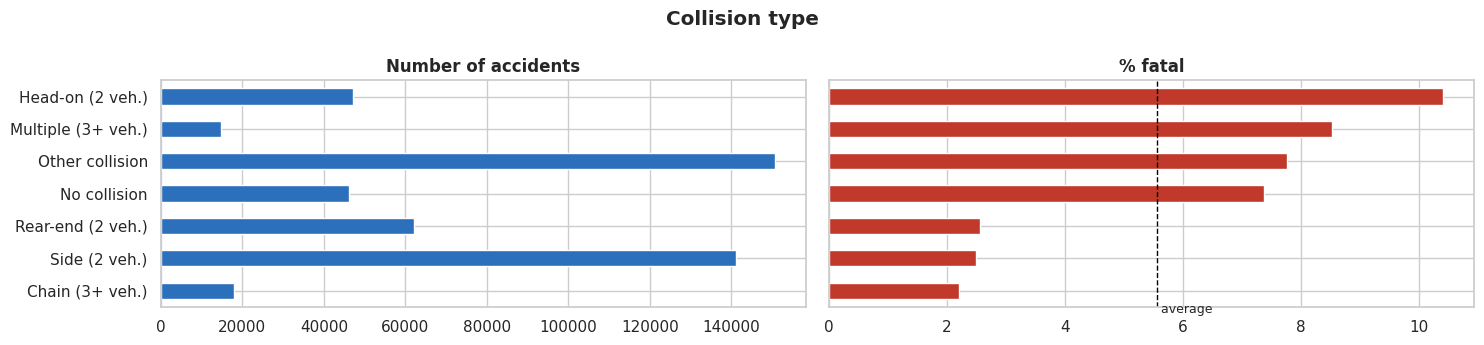

In [22]:
g = df.groupby("col_lbl").agg(accidents=("fatal", "size"), fatal_pct=("fatal", "mean"))
g = g[g["accidents"] >= 500]
g = g.sort_values('fatal_pct')
fig, axes = plt.subplots(1, 2, figsize=(15, max(3.5, len(g) * 0.42)))
g["accidents"].plot.barh(ax=axes[0], color=BLUE); axes[0].set_title("Number of accidents")
(g["fatal_pct"] * 100).plot.barh(ax=axes[1], color=RED); axes[1].set_title("% fatal")
avg = df["fatal"].mean() * 100
axes[1].axvline(avg, color="black", ls="--", lw=1); axes[1].text(avg, -0.7, " average", fontsize=9)
axes[1].set_yticklabels([])
for a in axes: a.set_ylabel("")
fig.suptitle("Collision type", fontweight="bold"); plt.tight_layout(); plt.show()

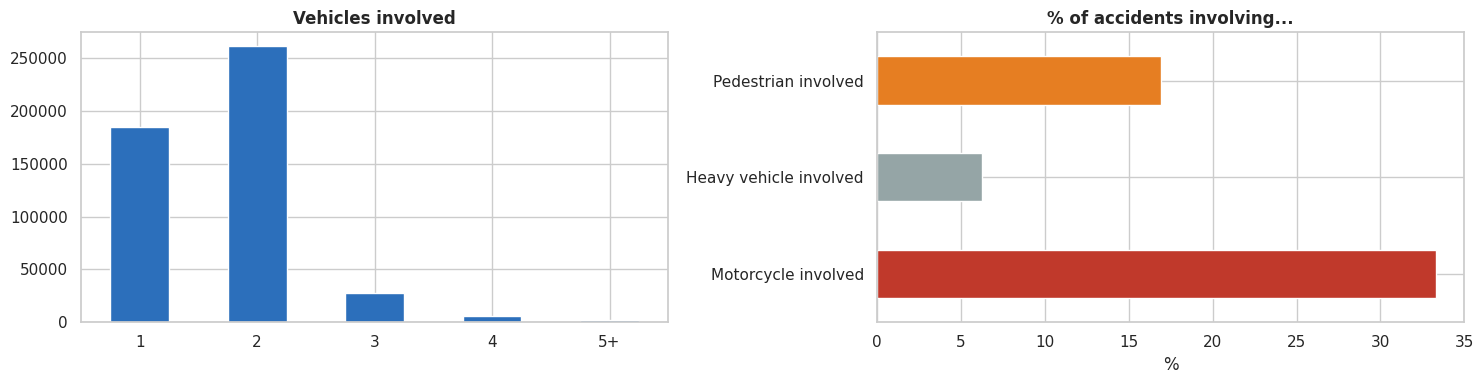

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
nv = df["post_n_vehicles"].clip(upper=5).value_counts().sort_index()
nv.index = [str(int(i)) if i < 5 else "5+" for i in nv.index]
nv.plot.bar(ax=axes[0], color=BLUE, rot=0); axes[0].set_title("Vehicles involved")
road_users = pd.Series({"Motorcycle involved": df["post_has_moto"].mean(),
                        "Heavy vehicle involved": df["post_has_heavy"].mean(),
                        "Pedestrian involved": df["post_has_pedestrian"].mean()}) * 100
road_users.plot.barh(ax=axes[1], color=[RED, GREY, "#e67e22"])
axes[1].set_title("% of accidents involving..."); axes[1].set_xlabel("%")
plt.tight_layout(); plt.show()

## 8. The exposure lesson: counts vs real risk
Raw counts say "17h is the most dangerous hour". But 17h simply has the most cars.

In `training_table.csv`, every accident is compared with "nothing happened" moments picked **like traffic** (many at 17h, few at 3h). The **accident rate** below therefore estimates risk **per passing car**.

Training table: 1,783,580 rows, 20% accidents


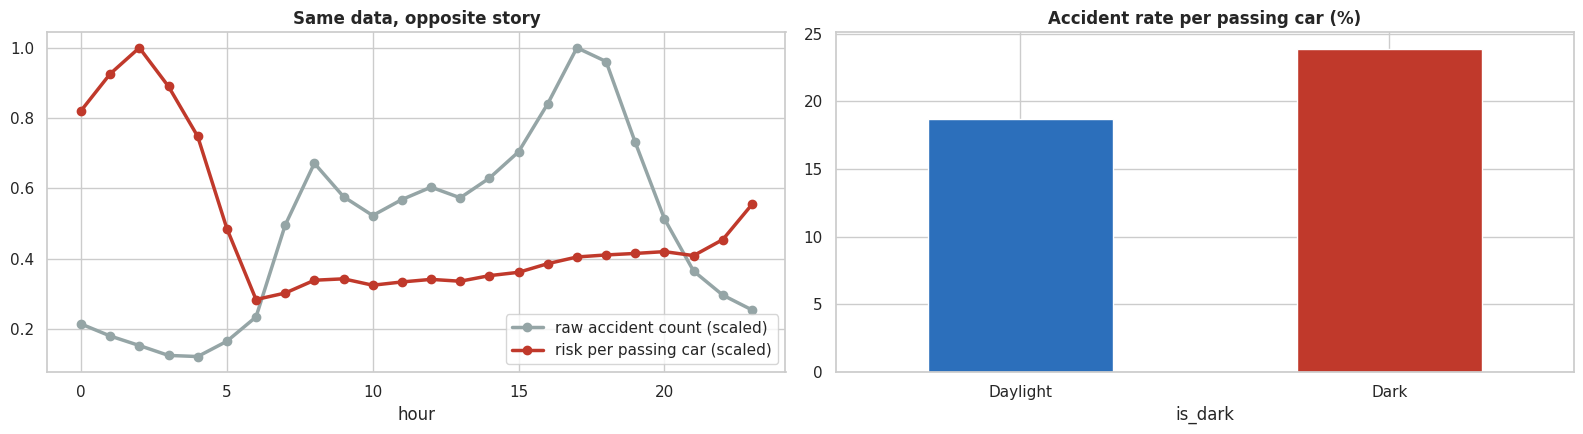

In [24]:
if TRAIN_PATH:
    t = pd.read_csv(TRAIN_PATH, parse_dates=["datetime"], low_memory=False)
    print(f"Training table: {len(t):,} rows, {t['label'].mean():.0%} accidents")
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
    raw = t[t.label == 1].groupby("hour").size()
    (raw / raw.max()).plot(ax=axes[0], color=GREY, lw=2.5, marker="o", label="raw accident count (scaled)")
    rate = t.groupby("hour")["label"].mean()
    (rate / rate.max()).plot(ax=axes[0], color=RED, lw=2.5, marker="o", label="risk per passing car (scaled)")
    axes[0].set_title("Same data, opposite story"); axes[0].legend(); axes[0].set_xlabel("hour")
    dk = t.groupby("is_dark")["label"].mean().rename({0: "Daylight", 1: "Dark"}) * 100
    dk.plot.bar(ax=axes[1], color=[BLUE, RED], rot=0)
    axes[1].set_title("Accident rate per passing car (%)")
    plt.tight_layout(); plt.show()
else:
    print("training_table.csv not found: upload it to the Kaggle dataset to see this part.")

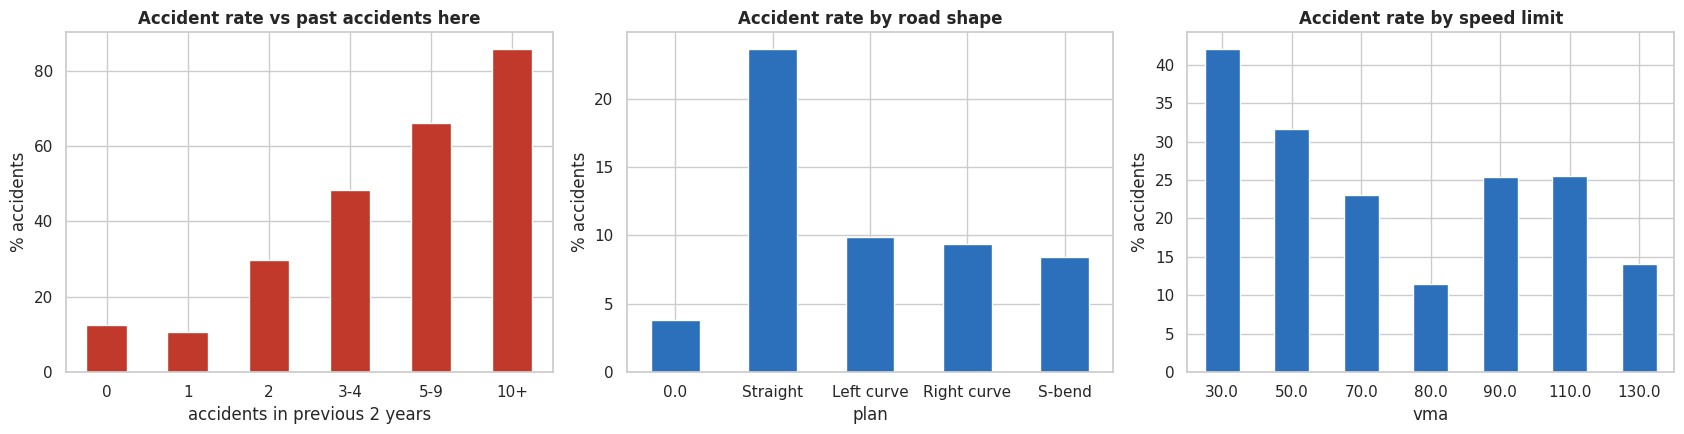

Past accidents should be the strongest signal: black spots stay black spots.


In [25]:
if TRAIN_PATH:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    bins = pd.cut(t["hist_n_acc"], [-1, 0, 1, 2, 4, 9, 1e9], labels=["0", "1", "2", "3-4", "5-9", "10+"])
    (t.groupby(bins)["label"].mean() * 100).plot.bar(ax=axes[0], color=RED, rot=0)
    axes[0].set_title("Accident rate vs past accidents here"); axes[0].set_xlabel("accidents in previous 2 years")
    pl = t.groupby("plan")["label"].mean().rename(LABELS["plan"]) * 100
    pl.plot.bar(ax=axes[1], color=BLUE, rot=0); axes[1].set_title("Accident rate by road shape")
    vm = t[t["vma"].isin([30, 50, 70, 80, 90, 110, 130])].groupby("vma")["label"].mean() * 100
    vm.plot.bar(ax=axes[2], color=BLUE, rot=0); axes[2].set_title("Accident rate by speed limit")
    for a in axes: a.set_ylabel("% accidents")
    plt.tight_layout(); plt.show()
    print("Past accidents should be the strongest signal: black spots stay black spots.")

## 9. Key findings
*Fill in with the numbers from the charts above, these become your pitch slides.*

| # | Finding | Number | What it means for our solution |
|---|---|---|---|
| 1 | Night accidents are deadlier | % fatal at 3h vs 15h | Stronger warnings at night |
| 2 | Per passing car, darkness is riskier | rate dark vs daylight | The model must use darkness, not raw counts |
| 3 | Speed limit drives severity | % fatal at 130 vs 50 | Speed is part of the risk score |
| 4 | Curves and outside-town roads are deadlier | % fatal curve vs straight | Road shape from OpenStreetMap is needed in Algeria |
| 5 | Risk concentrates in black spots | % of places with 1 accident vs top spots | Mapping Algerian black spots is high value |
| 6 | Bad weather / wet roads | % fatal by surface | Weather layer (Open-Meteo) |

**Limits to state honestly:** French data; police weather only exists for accidents; "hospitalized" definition changed in 2018 (so we use *fatal*); no traffic counts (approximated by a typical daily traffic curve).

In [26]:
"""
STEP 5: Train the risk model.

Input : training_table_weather.csv if it exists, otherwise training_table.csv
        (so the same script trains v1 without weather and v2 with weather)
Output: risk_model.txt      the trained model
        risk_model.json     the list of features it expects + test results

Install once:  pip install lightgbm scikit-learn
(on Mac, if lightgbm complains about "libomp":  brew install libomp)
"""
import glob
import json
from pathlib import Path

import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Features known BEFORE an accident (nothing that describes the crash itself)
ROAD = ["catr", "plan", "vma", "int", "agg", "circ", "nbv", "prof", "infra"]
TIME = ["hour", "weekday", "month", "is_weekend", "is_dark", "is_holiday"]
HISTORY = ["hist_n_acc", "hist_fatal_share"]
WEATHER = ["rain_mm", "rain_3h_mm", "is_fog", "is_snow", "is_storm", "is_rain"]
CATEGORICAL = ["catr", "plan", "int", "agg", "circ", "prof", "infra"]  # codes, not quantities

TEST_FROM = "2023-01-01"   # train on 2018-2022, test on 2023-2024 (the "future")


def main():
    # Looks in the current folder and in Kaggle inputs (/kaggle/input/...)
    def find(name):
        hits = glob.glob(name) + glob.glob(f"/kaggle/input/**/{name}", recursive=True)
        return hits[0] if hits else None
    src = find("training_table_weather.csv") or find("training_table.csv")
    t = pd.read_csv(src, parse_dates=["datetime"], low_memory=False)
    features = [c for c in ROAD + TIME + HISTORY + WEATHER if c in t.columns]
    with_weather = any(c in t.columns for c in WEATHER)
    print(f"Data: {src}  ({len(t):,} rows)  |  weather: {'yes' if with_weather else 'no'}")
    print(f"Features ({len(features)}): {', '.join(features)}")

    for c in CATEGORICAL:
        t[c] = t[c].astype("category")

    # ---------- Split by time: learn from the past, test on the future ----------
    train = t[t["datetime"] < TEST_FROM]
    test = t[t["datetime"] >= TEST_FROM]
    print(f"Train: {len(train):,} rows (2018-2022)  |  Test: {len(test):,} rows (2023-2024)")

    model = lgb.LGBMClassifier(
        n_estimators=2000, learning_rate=0.05, num_leaves=63,
        min_child_samples=200, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, verbose=-1)
    model.fit(train[features], train["label"],
              eval_set=[(test[features], test["label"])],
              eval_metric="auc",
              callbacks=[lgb.early_stopping(100, verbose=False)])

    # ---------- Results ----------
    p = model.predict_proba(test[features])[:, 1]
    auc = roc_auc_score(test["label"], p)
    # Of all real accidents in the test years, how many fall in the 10% / 20% riskiest predictions?
    order = np.argsort(-p)
    y = test["label"].to_numpy()[order]
    top10 = y[: len(y) // 10].sum() / y.sum()
    top20 = y[: len(y) // 5].sum() / y.sum()

    print("\n================ RESULTS ================")
    print(f"AUC: {auc:.3f}   (0.5 = coin flip, 1.0 = perfect)")
    print(f"The 10% riskiest situations contain {top10:.0%} of real accidents (random would be 10%)")
    print(f"The 20% riskiest situations contain {top20:.0%} of real accidents (random would be 20%)")

    imp = pd.Series(model.booster_.feature_importance("gain"), index=features)
    imp = (imp / imp.sum()).sort_values(ascending=False)
    print("\nWhat the model relies on most:")
    for f, v in imp.items():
        print(f"  {f:18s} {'#' * int(v * 60):s} {v:.1%}")

    # ---------- Save ----------
    model.booster_.save_model("risk_model.txt")
    Path("risk_model.json").write_text(json.dumps({
        "features": features, "categorical": [c for c in CATEGORICAL if c in features],
        "with_weather": with_weather, "test_auc": round(auc, 4),
        "top10_capture": round(float(top10), 4), "top20_capture": round(float(top20), 4),
    }, indent=2))
    print("\nSaved -> risk_model.txt + risk_model.json")


if __name__ == "__main__":
    main()

Data: /kaggle/input/datasets/moussaballou/training-table-csv/training_table.csv  (1,783,580 rows)  |  weather: no
Features (16): catr, plan, vma, int, agg, circ, nbv, prof, infra, hour, weekday, month, is_weekend, is_dark, hist_n_acc, hist_fatal_share
Train: 1,256,119 rows (2018-2022)  |  Test: 527,461 rows (2023-2024)

================ RESULTS ================
AUC: 0.824   (0.5 = coin flip, 1.0 = perfect)
The 10% riskiest situations contain 38% of real accidents (random would be 10%)
The 20% riskiest situations contain 56% of real accidents (random would be 20%)

What the model relies on most:
  hist_fatal_share   ############################# 48.4%
  hist_n_acc         ################# 29.0%
  vma                #### 8.1%
  hour               ## 4.8%
  plan                1.7%
  weekday             1.5%
  circ                1.0%
  month               1.0%
  catr                1.0%
  nbv                 0.8%
  int                 0.7%
  agg                 0.6%
  prof              

In [28]:
"""
STEP 5: Train the risk model.

Input : training_table_weather.csv if it exists, otherwise training_table.csv
        (so the same script trains v1 without weather and v2 with weather)
Output: risk_model.txt      the trained model
        risk_model.json     the list of features it expects + test results

Install once:  pip install lightgbm scikit-learn
(on Mac, if lightgbm complains about "libomp":  brew install libomp)
"""
import glob
import json
from pathlib import Path

import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Features known BEFORE an accident (nothing that describes the crash itself)
ROAD = ["catr", "plan", "vma", "int", "agg", "circ", "nbv", "prof", "infra"]
TIME = ["hour", "weekday", "month", "is_weekend", "is_dark", "is_holiday"]
HISTORY = ["hist_n_acc", "hist_fatal_share"]
WEATHER = ["rain_mm", "rain_3h_mm", "is_fog", "is_snow", "is_storm", "is_rain"]
CATEGORICAL = ["catr", "plan", "int", "agg", "circ", "prof", "infra"]  # codes, not quantities

TEST_FROM = "2023-01-01"   # train on 2018-2022, test on 2023-2024 (the "future")
USE_HISTORY = False        # False = "Algeria mode": road + time only, no past accidents
NAME = "risk_model" if USE_HISTORY else "risk_model_nohist"


def main():
    # Looks in the current folder and in Kaggle inputs (/kaggle/input/...)
    def find(name):
        hits = glob.glob(name) + glob.glob(f"/kaggle/input/**/{name}", recursive=True)
        return hits[0] if hits else None
    src = find("training_table_weather.csv") or find("training_table.csv")
    t = pd.read_csv(src, parse_dates=["datetime"], low_memory=False)
    features = [c for c in ROAD + TIME + (HISTORY if USE_HISTORY else []) + WEATHER
                if c in t.columns]
    with_weather = any(c in t.columns for c in WEATHER)
    print(f"Data: {src}  ({len(t):,} rows)  |  weather: {'yes' if with_weather else 'no'}")
    print(f"Features ({len(features)}): {', '.join(features)}")

    for c in CATEGORICAL:
        t[c] = t[c].astype("category")

    # ---------- Split by time: learn from the past, test on the future ----------
    train = t[t["datetime"] < TEST_FROM]
    test = t[t["datetime"] >= TEST_FROM]
    print(f"Train: {len(train):,} rows (2018-2022)  |  Test: {len(test):,} rows (2023-2024)")

    model = lgb.LGBMClassifier(
        n_estimators=2000, learning_rate=0.05, num_leaves=63,
        min_child_samples=200, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, verbose=-1)
    model.fit(train[features], train["label"],
              eval_set=[(test[features], test["label"])],
              eval_metric="auc",
              callbacks=[lgb.early_stopping(100, verbose=False)])

    # ---------- Results ----------
    p = model.predict_proba(test[features])[:, 1]
    auc = roc_auc_score(test["label"], p)
    # Of all real accidents in the test years, how many fall in the 10% / 20% riskiest predictions?
    order = np.argsort(-p)
    y = test["label"].to_numpy()[order]
    top10 = y[: len(y) // 10].sum() / y.sum()
    top20 = y[: len(y) // 5].sum() / y.sum()

    print("\n================ RESULTS ================")
    print(f"AUC: {auc:.3f}   (0.5 = coin flip, 1.0 = perfect)")
    print(f"The 10% riskiest situations contain {top10:.0%} of real accidents (random would be 10%)")
    print(f"The 20% riskiest situations contain {top20:.0%} of real accidents (random would be 20%)")

    imp = pd.Series(model.booster_.feature_importance("gain"), index=features)
    imp = (imp / imp.sum()).sort_values(ascending=False)
    print("\nWhat the model relies on most:")
    for f, v in imp.items():
        print(f"  {f:18s} {'#' * int(v * 60):s} {v:.1%}")

    # ---------- Save ----------
    model.booster_.save_model(f"{NAME}.txt")
    Path(f"{NAME}.json").write_text(json.dumps({
        "features": features, "categorical": [c for c in CATEGORICAL if c in features],
        "with_weather": with_weather, "with_history": USE_HISTORY, "test_auc": round(auc, 4),
        "top10_capture": round(float(top10), 4), "top20_capture": round(float(top20), 4),
    }, indent=2))
    print(f"\nSaved -> {NAME}.txt + {NAME}.json")


if __name__ == "__main__":
    main()

Data: /kaggle/input/datasets/moussaballou/training-table-csv/training_table.csv  (1,783,580 rows)  |  weather: no
Features (14): catr, plan, vma, int, agg, circ, nbv, prof, infra, hour, weekday, month, is_weekend, is_dark
Train: 1,256,119 rows (2018-2022)  |  Test: 527,461 rows (2023-2024)

================ RESULTS ================
AUC: 0.799   (0.5 = coin flip, 1.0 = perfect)
The 10% riskiest situations contain 31% of real accidents (random would be 10%)
The 20% riskiest situations contain 51% of real accidents (random would be 20%)

What the model relies on most:
  vma                ##################### 35.6%
  catr               ####### 12.1%
  nbv                ##### 9.8%
  hour               #### 7.5%
  agg                #### 7.5%
  plan               #### 7.5%
  circ               #### 7.3%
  int                ## 4.0%
  weekday            # 2.3%
  infra              # 2.3%
  prof               # 1.9%
  month               1.4%
  is_dark             0.4%
  is_weekend         

In [29]:
"""
Test the trained model on hand-made situations ("use cases").

Needs: risk_model_nohist.txt + risk_model_nohist.json  (or risk_model.txt/.json)
On Kaggle: run it in the same notebook right after training, or upload the 2 files.

How to read the result:
  "x vs average" = how much riskier than an average situation in the training data
  (1.0 = average, 2.0 = twice the average, 0.5 = half)
"""
import glob
import json

import lightgbm as lgb
import numpy as np
import pandas as pd

MODEL = "risk_model_nohist"   # or "risk_model" (with history)

# Codes (same as the French data):
#  catr: 1 motorway, 2 national road, 3 departmental road, 4 municipal road
#  circ: 1 one-way, 2 two-way, 3 separated carriageways
#  agg : 1 outside town, 2 in town
#  plan: 1 straight, 2 left curve, 3 right curve, 4 S-bend
#  int : 1 no intersection, 2 X junction, 3 T junction, 6 roundabout
#  prof: 1 flat, 2 slope        infra: 0 none
#  weekday: 0 Monday ... 6 Sunday
SCENARIOS = {
    "City street, Friday 17h (rush hour)":
        dict(catr=4, vma=50, nbv=2, circ=2, agg=2, plan=1, int=1, prof=1, infra=0,
             hour=17, weekday=4, month=10, is_dark=0),
    "Same city street, Tuesday 4h (empty, dark)":
        dict(catr=4, vma=50, nbv=2, circ=2, agg=2, plan=1, int=1, prof=1, infra=0,
             hour=4, weekday=1, month=10, is_dark=1),
    "City roundabout, Friday 17h":
        dict(catr=4, vma=50, nbv=2, circ=2, agg=2, plan=1, int=6, prof=1, infra=0,
             hour=17, weekday=4, month=10, is_dark=0),
    "Rural road, curve, 80 km/h, Saturday 2h (dark)":
        dict(catr=3, vma=80, nbv=2, circ=2, agg=1, plan=2, int=1, prof=2, infra=0,
             hour=2, weekday=5, month=7, is_dark=1),
    "Same rural curve, Tuesday 11h (daylight)":
        dict(catr=3, vma=80, nbv=2, circ=2, agg=1, plan=2, int=1, prof=2, infra=0,
             hour=11, weekday=1, month=7, is_dark=0),
    "National road (like an Algerian RN), two-way, 90 km/h, Sunday 23h":
        dict(catr=2, vma=90, nbv=2, circ=2, agg=1, plan=1, int=3, prof=1, infra=0,
             hour=23, weekday=6, month=8, is_dark=1),
    "Motorway, 130 km/h, 3 lanes, Wednesday 10h":
        dict(catr=1, vma=130, nbv=3, circ=3, agg=1, plan=1, int=1, prof=1, infra=0,
             hour=10, weekday=2, month=5, is_dark=0),
}


def find(name):
    hits = glob.glob(name) + glob.glob(f"/kaggle/working/{name}") \
        + glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    return hits[0] if hits else None


def level(x):
    return ("🟢 low" if x < 0.7 else "🟡 medium" if x < 1.5
            else "🟠 high" if x < 3 else "🔴 very high")


def main():
    info = json.load(open(find(f"{MODEL}.json")))
    booster = lgb.Booster(model_file=find(f"{MODEL}.txt"))
    features, cats = info["features"], info["categorical"]

    rows = []
    for s in SCENARIOS.values():
        r = {f: np.nan for f in features}            # unknown features stay empty
        r.update({k: v for k, v in s.items() if k in features})
        r["is_weekend"] = int(s["weekday"] >= 5)
        rows.append(r)
    X = pd.DataFrame(rows)[features].astype(float)
    for c in cats:
        X[c] = X[c].astype("category")               # model maps them to its own categories

    p = booster.predict(X)
    base = 0.2                                        # 1 accident for 4 "nothing happened"
    x_avg = (p / (1 - p)) / (base / (1 - base))

    print(f"Model: {MODEL}  (AUC on 2023-2024: {info['test_auc']})\n")
    res = pd.DataFrame({"scenario": list(SCENARIOS), "x vs average": x_avg.round(2),
                        "level": [level(v) for v in x_avg]})
    res = res.sort_values("x vs average", ascending=False)
    print(res.to_string(index=False))


if __name__ == "__main__":
    main()

Model: risk_model_nohist  (AUC on 2023-2024: 0.7991)

                                                         scenario  x vs average       level
                   Rural road, curve, 80 km/h, Saturday 2h (dark)          5.49 🔴 very high
                              City street, Friday 17h (rush hour)          4.06 🔴 very high
                       Same city street, Tuesday 4h (empty, dark)          2.97      🟠 high
                                      City roundabout, Friday 17h          2.41      🟠 high
National road (like an Algerian RN), two-way, 90 km/h, Sunday 23h          0.85    🟡 medium
                       Motorway, 130 km/h, 3 lanes, Wednesday 10h          0.59       🟢 low
                         Same rural curve, Tuesday 11h (daylight)          0.43       🟢 low


In [30]:
import lightgbm as lgb, pandas as pd, json
m = lgb.Booster(model_file="risk_model_nohist.txt"); f = json.load(open("risk_model_nohist.json"))
t = pd.read_csv("/kaggle/input/datasets/moussaballou/training-table-csv/training_table.csv", nrows=20)
print(pd.DataFrame({"real": t["label"], "predicted": m.predict(t[f["features"]].astype({c: "category" for c in f["categorical"]})).round(3)}))

    real  predicted
0      0      0.057
1      0      0.068
2      0      0.344
3      1      0.271
4      0      0.077
5      0      0.062
6      0      0.105
7      0      0.038
8      0      0.056
9      0      0.076
10     0      0.098
11     1      0.333
12     1      0.264
13     0      0.309
14     0      0.304
15     1      0.423
16     0      0.071
17     0      0.048
18     1      0.145
19     0      0.169


In [31]:
print(m.num_trees())

123


In [1]:
"""
STEP 5: Train the risk model.

Input : training_table_weather.csv if it exists, otherwise training_table.csv
        (so the same script trains v1 without weather and v2 with weather)
Output: risk_model.txt      the trained model
        risk_model.json     the list of features it expects + test results

Install once:  pip install lightgbm scikit-learn
(on Mac, if lightgbm complains about "libomp":  brew install libomp)
"""
import glob
import json
from pathlib import Path

import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Features known BEFORE an accident (nothing that describes the crash itself)
ROAD = ["catr", "plan", "vma", "int", "agg", "circ", "nbv", "prof", "infra"]
TIME = ["hour", "weekday", "month", "is_weekend", "is_dark", "is_holiday"]
HISTORY = ["hist_n_acc", "hist_fatal_share"]
WEATHER = ["rain_mm", "rain_3h_mm", "is_fog", "is_snow", "is_storm", "is_rain"]
CATEGORICAL = ["catr", "plan", "int", "agg", "circ", "prof", "infra"]  # codes, not quantities

TEST_FROM = "2023-01-01"   # train on 2018-2022, test on 2023-2024 (the "future")
USE_HISTORY = False        # False = "Algeria mode": road + time only, no past accidents
NAME = "risk_model" if USE_HISTORY else "risk_model_nohist"


def main():
    # Looks in the current folder and in Kaggle inputs (/kaggle/input/...)
    def find(name):
        hits = glob.glob(name) + glob.glob(f"/kaggle/input/**/{name}", recursive=True)
        return hits[0] if hits else None
    src = find("training_table_weather.csv") or find("training_table.csv")
    t = pd.read_csv(src, parse_dates=["datetime"], low_memory=False)
    features = [c for c in ROAD + TIME + (HISTORY if USE_HISTORY else []) + WEATHER
                if c in t.columns]
    with_weather = any(c in t.columns for c in WEATHER)
    print(f"Data: {src}  ({len(t):,} rows)  |  weather: {'yes' if with_weather else 'no'}")
    print(f"Features ({len(features)}): {', '.join(features)}")

    for c in CATEGORICAL:
        t[c] = t[c].astype("category")

    # ---------- Split by time: learn from the past, test on the future ----------
    train = t[t["datetime"] < TEST_FROM]
    test = t[t["datetime"] >= TEST_FROM]
    print(f"Train: {len(train):,} rows (2018-2022)  |  Test: {len(test):,} rows (2023-2024)")

    model = lgb.LGBMClassifier(
        n_estimators=2000, learning_rate=0.05, num_leaves=63,
        min_child_samples=200, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, verbose=-1)
    model.fit(train[features], train["label"],
              eval_set=[(test[features], test["label"])],
              eval_metric="auc",
              callbacks=[lgb.early_stopping(100, verbose=False)])

    # ---------- Results ----------
    p = model.predict_proba(test[features])[:, 1]
    auc = roc_auc_score(test["label"], p)
    # Of all real accidents in the test years, how many fall in the 10% / 20% riskiest predictions?
    order = np.argsort(-p)
    y = test["label"].to_numpy()[order]
    top10 = y[: len(y) // 10].sum() / y.sum()
    top20 = y[: len(y) // 5].sum() / y.sum()

    print("\n================ RESULTS ================")
    print(f"AUC: {auc:.3f}   (0.5 = coin flip, 1.0 = perfect)")
    print(f"The 10% riskiest situations contain {top10:.0%} of real accidents (random would be 10%)")
    print(f"The 20% riskiest situations contain {top20:.0%} of real accidents (random would be 20%)")

    imp = pd.Series(model.booster_.feature_importance("gain"), index=features)
    imp = (imp / imp.sum()).sort_values(ascending=False)
    print("\nWhat the model relies on most:")
    for f, v in imp.items():
        print(f"  {f:18s} {'#' * int(v * 60):s} {v:.1%}")

    # ---------- Save ----------
    model.booster_.save_model(f"{NAME}.txt")
    Path(f"{NAME}.json").write_text(json.dumps({
        "features": features, "categorical": [c for c in CATEGORICAL if c in features],
        "with_weather": with_weather, "with_history": USE_HISTORY, "test_auc": round(auc, 4),
        "top10_capture": round(float(top10), 4), "top20_capture": round(float(top20), 4),
    }, indent=2))
    print(f"\nSaved -> {NAME}.txt + {NAME}.json")


if __name__ == "__main__":
    main()

Data: /kaggle/input/datasets/moussaballou/training-table-weather-csv/training_table_weather.csv  (1,783,580 rows)  |  weather: yes
Features (20): catr, plan, vma, int, agg, circ, nbv, prof, infra, hour, weekday, month, is_weekend, is_dark, rain_mm, rain_3h_mm, is_fog, is_snow, is_storm, is_rain
Train: 1,256,119 rows (2018-2022)  |  Test: 527,461 rows (2023-2024)

================ RESULTS ================
AUC: 0.800   (0.5 = coin flip, 1.0 = perfect)
The 10% riskiest situations contain 32% of real accidents (random would be 10%)
The 20% riskiest situations contain 52% of real accidents (random would be 20%)

What the model relies on most:
  vma                ###################### 37.3%
  catr               ####### 12.3%
  nbv                ##### 9.7%
  hour               #### 7.5%
  plan               #### 6.8%
  circ               ### 6.4%
  agg                ### 5.4%
  int                ## 4.1%
  infra              # 2.3%
  weekday            # 2.3%
  prof               # 2.2%
  